In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.utils import resample
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from imblearn.over_sampling import SMOTE
from collections import Counter

In [3]:

df = pd.read_csv("fakenews.csv")

# Remove rows with missing labels
df = df.dropna(subset=["label"]).copy()

In [4]:
# Display label distribution
print("Class Distribution:")
print(df["label"].value_counts())

# Calculate class percentages
print("\nClass Percentages:")
print((df["label"].value_counts(normalize=True) * 100).round(2))


Class Distribution:
label
Fake    1110
Real    1102
Name: count, dtype: int64

Class Percentages:
label
Fake    50.18
Real    49.82
Name: proportion, dtype: float64


In [5]:
# Calculate imbalance ratio
counts = df["label"].value_counts()

if len(counts) >= 2 and counts.min() > 0:
    imbalance_ratio = counts.max() / counts.min()
    print("\nImbalance Ratio:", round(imbalance_ratio, 2))
else:
    print("\nImbalance ratio cannot be calculated.")


Imbalance Ratio: 1.01


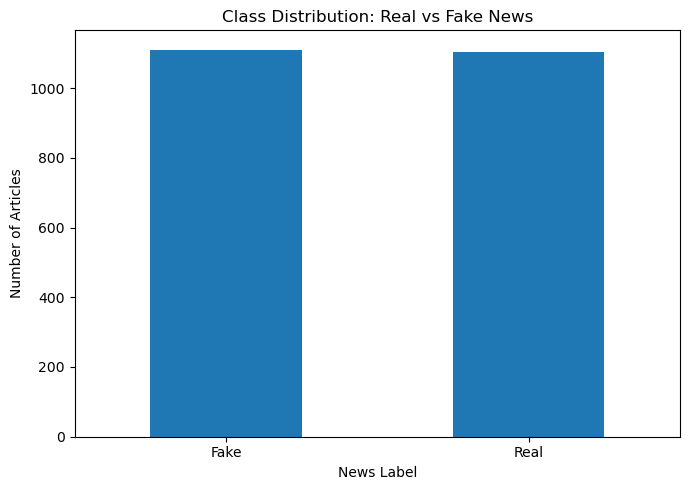

In [6]:
# Plot class distribution
df["label"].value_counts().plot(
    kind="bar",
    figsize=(7, 5)
)
plt.title("Class Distribution: Real vs Fake News")
plt.xlabel("News Label")
plt.ylabel("Number of Articles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [7]:
# Combine headline and body text
df["text"] = (
    df["headline"].fillna("").astype(str)
    + " "
    + df["body_text"].fillna("").astype(str)
)


In [8]:
# Separate features and target
X = df["text"]
y = df["label"]
# Split data before vectorization and resampling
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Convert text into TF-IDF features
vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=5000
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("\nTraining Distribution Before Resampling:")
print(Counter(y_train))



Training Distribution Before Resampling:
Counter({'Fake': 888, 'Real': 881})


In [9]:
# SMOTE requires enough minority-class samples
min_class_count = y_train.value_counts().min()

if min_class_count >= 2:
    k = min(5, min_class_count - 1)

    smote = SMOTE(
        random_state=42,
        k_neighbors=k
    )

    X_smote, y_smote = smote.fit_resample(
        X_train_tfidf,
        y_train
    )

    print("\nDistribution After SMOTE:")
    print(Counter(y_smote))
else:
    print("\nSMOTE skipped: insufficient minority-class samples.")



Distribution After SMOTE:
Counter({'Real': 888, 'Fake': 888})


In [10]:
# Random undersampling
train_df = pd.DataFrame({
    "text": X_train.reset_index(drop=True),
    "label": y_train.reset_index(drop=True)
})

majority_label = train_df["label"].value_counts().idxmax()
minority_label = train_df["label"].value_counts().idxmin()

majority = train_df[train_df["label"] == majority_label]
minority = train_df[train_df["label"] == minority_label]


In [11]:
if len(majority) > len(minority):
    majority_downsampled = resample(
        majority,
        replace=False,
        n_samples=len(minority),
        random_state=42
    )

    undersampled_df = pd.concat([
        majority_downsampled,
        minority
    ])

    print("\nDistribution After Undersampling:")
    print(undersampled_df["label"].value_counts())
else:
    print("\nUndersampling not required: classes are balanced.")

print("\nClass imbalance analysis completed.")


Distribution After Undersampling:
label
Fake    881
Real    881
Name: count, dtype: int64

Class imbalance analysis completed.
